In [1]:
import logging

import numpy as np
import optimistix as optx

from atmodeller import (
    InteriorAtmosphere,
    Planet,
    SolverParameters,
    Species,
    SpeciesCollection,
    debug_logger,
)
from atmodeller.eos import get_eos_models
from atmodeller.solubility import get_solubility_models
from atmodeller.thermodata import IronWustiteBuffer

logger = debug_logger()
logger.setLevel(logging.INFO)
# For more output use DEBUG
# logger.setLevel(logging.DEBUG)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import optimistix as optx
from atmodeller import (
    InteriorAtmosphere,
    Planet,
    SolverParameters,
    Species,
    SpeciesCollection,
    debug_logger,
)
from atmodeller.eos import get_eos_models, IdealGas
from atmodeller.solubility import get_solubility_models
from atmodeller.thermodata import IronWustiteBuffer

Atmodeller initialized with double precision (float64)


# Sub-Neptune (e.g. K2-18b) models from Bower et al. (2025)

The code blocks below must always be run, but then you can preferentially run only the models for ideal or real gases.

Parameters for the simulations

In [2]:
number_of_realisations = 50
surface_temperature = 3000  # K

# For simulations with fixed mass and surface radius:
planet_mass = 5.154e25
surface_radius = 1.1225e7  # using M-R relation from Hakim+2018
mantle_melt_fraction = 1.0  # 0.1

RANDOM_SEED = 0
np.random.seed(RANDOM_SEED)

In [3]:
eos_models = get_eos_models()
sol_models = get_solubility_models()

# Gases 
H2O_gs = Species.create_gas(
    "H2O", 
    solubility=sol_models["H2O_peridotite_sossi23"]
    )
H2O_rgs = Species.create_gas(
    "H2O", 
    activity=eos_models["H2O_cork_holland98"],
    solubility=sol_models["H2O_peridotite_sossi23"]
    )

H2_gs = Species.create_gas(
    "H2", 
    solubility=sol_models["H2_basalt_hirschmann12"]
    )
H2_rgs = Species.create_gas(
    "H2", 
    activity=eos_models["H2_chabrier21"], 
    solubility=sol_models["H2_basalt_hirschmann12"]
    )

O2_g = Species.create_gas(
    "O2"
    )
O2_rg = Species.create_gas(
    "O2", 
    activity=eos_models["O2_cs_shi92"]
    )


CO2_gs = Species.create_gas(
    "CO2", solubility=sol_models["CO2_basalt_dixon95"]
)

CO2_rgs = Species.create_gas(
    "CO2", solubility=sol_models["CO2_basalt_dixon95"], activity=eos_models["CO2_cs_shi92"]
)

CO_gs = Species.create_gas(
    "CO", solubility=sol_models["CO_basalt_yoshioka19"]
)
CO_rgs = Species.create_gas(
    "CO", solubility=sol_models["CO_basalt_yoshioka19"], activity=eos_models["CO_cs_shi92"]
)

CH4_gs = Species.create_gas(
    "CH4", solubility=sol_models["CH4_basalt_ardia13"]
)
CH4_rgs = Species.create_gas(
    "CH4", solubility=sol_models["CH4_basalt_ardia13"], activity=eos_models["CH4_cs_shi92"]
)

N2_gs = Species.create_gas(
    "N2", solubility=sol_models["N2_basalt_libourel03"]
)
N2_rgs = Species.create_gas(
    "N2", solubility=sol_models["N2_basalt_libourel03"], activity=eos_models["N2_cs_saxena87"]
)

NH3_g = Species.create_gas("H3N")
NH3_rg = Species.create_gas("H3N", activity=eos_models["H3N_rk49_reid87"])


CHN_g = Species.create_gas("CHN")
CHN_rg = Species.create_gas("CHN", activity=eos_models["CHN_rk49_reid87"])

He_gs = Species.create_gas(
    "He", solubility=sol_models["He_basalt_jambon86"]
)
He_rgs = Species.create_gas(
    "He", solubility=sol_models["He_basalt_jambon86"], activity=eos_models["He_chabrier21"]
)


species_ideal = SpeciesCollection(
    (
        H2O_gs,
        H2_gs,
        O2_g,
        CO2_gs,
        CO_gs,
        CH4_gs,
        N2_gs,
        NH3_g,
        CHN_g,
        He_gs,
    )
)

species_real = SpeciesCollection(
    (
        H2O_rgs,
        H2_rgs,
        O2_rg,
        CO2_rgs,
        CO_rgs,
        CH4_rgs,
        N2_rgs,
        NH3_rg,
        CHN_rg,
        He_rgs,
    )
)

In [4]:
import numpy as np

# ===========================================================
# 1. Asplund solar composition mass fractions (wt%)
# ===========================================================
H_masspercent_lodders09  = 73.9
He_masspercent_lodders09 = 24.69
C_masspercent_lodders09  = 0.265
N_masspercent_lodders09  = 0.085


# Ratios relative to hydrogen (Solar)
C_H_RATIO_SOLAR  = C_masspercent_lodders09  / H_masspercent_lodders09
N_H_RATIO_SOLAR  = N_masspercent_lodders09  / H_masspercent_lodders09
He_H_RATIO_SOLAR = He_masspercent_lodders09 / H_masspercent_lodders09


# ===========================================================
# 2. Function to get metal-enriched budgets
# ===========================================================
def get_enriched_budget(h_kg, metallicity_factor=100):
    """
    Returns C, N, O, and He masses based on solar H ratios,
    with C, N, O enriched by metallicity_factor × solar.
    He stays fixed at the solar He/H ratio.
    """
    return {
        "H":  h_kg,
        "C":  h_kg * C_H_RATIO_SOLAR  * metallicity_factor,
        "N":  h_kg * N_H_RATIO_SOLAR  * metallicity_factor,
        "He": h_kg * He_H_RATIO_SOLAR
    }


# ===========================================================
# 3. Hydrogen mass fraction range: 0.1% → 10% of total planet mass
# ===========================================================
number_of_realisations = 50   # choose as needed

# Hydrogen mass fractions between 0.001 and 0.10
H_mass_fraction = np.logspace(-3, -1, number_of_realisations)
fO2_log10_shifts = np.full(number_of_realisations, -3)

# Convert mass fraction → hydrogen mass in kg
h_kg = H_mass_fraction * planet_mass

mass_constraints = get_enriched_budget(h_kg, metallicity_factor=100)

In [10]:
sub_neptune = Planet(
    surface_temperature=surface_temperature,
    planet_mass=planet_mass,
    surface_radius=surface_radius,
    mantle_melt_fraction=mantle_melt_fraction,
)

In [12]:
solver = optx.LevenbergMarquardt
solver_parameters = SolverParameters(solver=solver)

model_real_varyHF_withsol = InteriorAtmosphere(species_ideal)

fugacity_constraints = {O2_rg.name: IronWustiteBuffer(fO2_log10_shifts)}

model_real_varyHF_withsol.solve(
    planet=sub_neptune,
    mass_constraints=mass_constraints,
    fugacity_constraints=fugacity_constraints,
    # Use the ideal solution for the initial guess of the real case
    solver_parameters=solver_parameters,
)
output_real_varyHF_withsol = model_real_varyHF_withsol.output

# Write the complete solution to Excel
output_real_varyHF_withsol.to_excel("IDEALEST")

# Write the data to a pickle file with dataframes
output_real_varyHF_withsol.to_pickle("IDEALEST")

[16:51:40 - atmodeller.classes             - INFO     ] - species = ('H2O_g: IdealGas, SolubilityPowerLaw', 'H2_g: IdealGas, SolubilityPowerLawLog10', 'O2_g: IdealGas, NoSolubility', 'CO2_g: IdealGas, _CO2_basalt_dixon95', 'CO_g: IdealGas, _CO_basalt_yoshioka19', 'CH4_g: IdealGas, _CH4_basalt_ardia13', 'N2_g: IdealGas, _N2_basalt_libourel03', 'H3N_g: IdealGas, NoSolubility', 'CHN_g: IdealGas, NoSolubility', 'He_g: IdealGas, SolubilityPowerLaw')
[16:51:40 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[16:51:40 - atmodeller.classes             - INFO     ] - reactions = {0: '2.0 H2_g + 2.0 CO_g = 1.0 CO2_g + 1.0 CH4_g',
 1: '1.0 H2_g + 1.0 CO2_g = 1.0 H2O_g + 1.0 CO_g',
 2: '1.5 H2_g + 0.5 N2_g = 1.0 H3N_g',
 3: '0.5 H2_g + 2.0 CO_g + 0.5 N2_g = 1.0 CO2_g + 1.0 CHN_g',
 4: '2.0 CO2_g = 1.0 O2_g + 2.0 CO_g'}
[16:51:40 - atmodeller.classes             - INFO     ] - Attempting to solve 50 model(s)
[16:51:43 - atmodeller.cl

In [11]:
solver = optx.LevenbergMarquardt
solver_parameters = SolverParameters(solver=solver)

model_real_varyHF_withsol = InteriorAtmosphere(species_real)

fugacity_constraints = {O2_rg.name: IronWustiteBuffer(fO2_log10_shifts)}

model_real_varyHF_withsol.solve(
    planet=sub_neptune,
    mass_constraints=mass_constraints,
    fugacity_constraints=fugacity_constraints,
    # Use the ideal solution for the initial guess of the real case
    solver_parameters=solver_parameters,
)
output_real_varyHF_withsol = model_real_varyHF_withsol.output

# Write the complete solution to Excel
output_real_varyHF_withsol.to_excel("THEREALEST")

# Write the data to a pickle file with dataframes
output_real_varyHF_withsol.to_pickle("THEREALEST")

[16:49:01 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13', 'N2_g: CombinedRealGas, _N2_basalt_libourel03', 'H3N_g: RedlichKwong49, NoSolubility', 'CHN_g: RedlichKwong49, NoSolubility', 'He_g: CombinedRealGas, SolubilityPowerLaw')
[16:49:01 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[16:49:01 - atmodeller.classes             - INFO     ] - reactions = {0: '2.0 H2_g + 2.0 CO_g = 1.0 CO2_g + 1.0 CH4_g',
 1: '1.0 H2_g + 1.0 CO2_g = 1.0 H2O_g + 1.0 CO_g',
 2: '1.5 H2_g + 0.5 N2_g = 1.0 H3N_g',
 3: '0.5 H2_g + 2.0 CO_g + 0.5 N2_g = 1.0 CO2_g + 1.0 CHN_g',
 4: '2.0 CO2_g = 1.0 O2_g + 2.0 CO_g'}
[16:49:01 - atmodeller.classes             - IN

/var/folders/l6/yw7hsmzx1czfjt3n32sfq_w00000gn/T/ipykernel_65803/558321485.py:29: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = get_cmap("Set3")


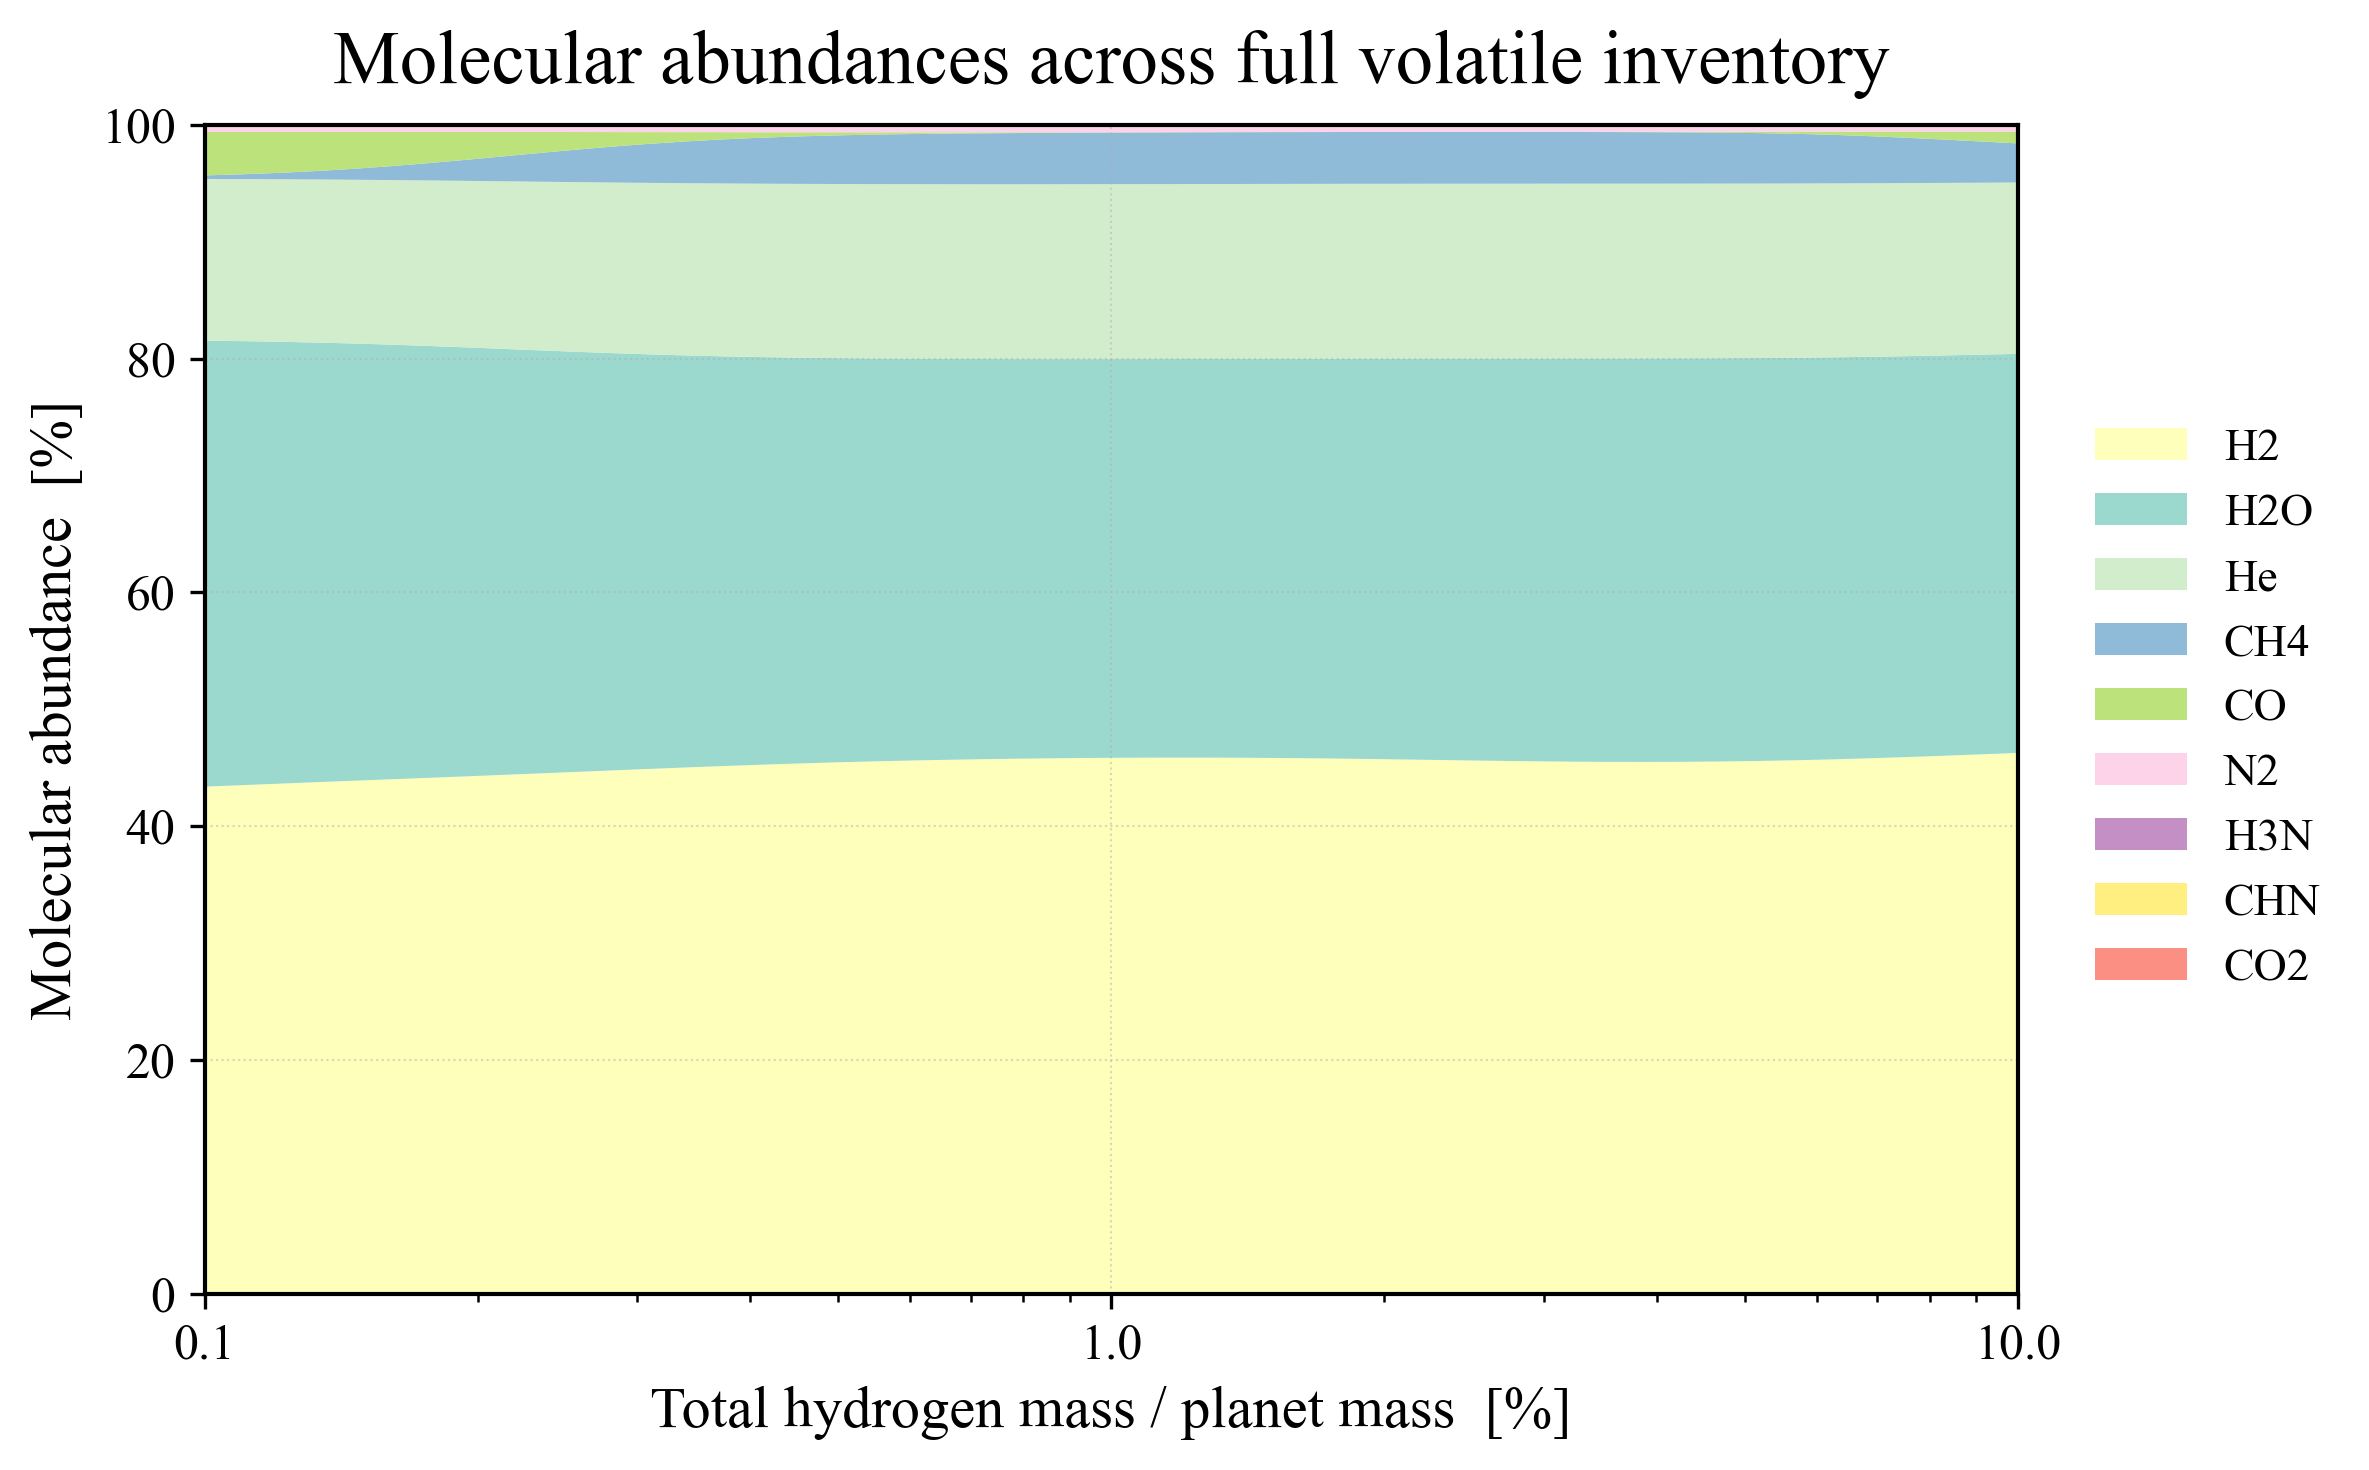

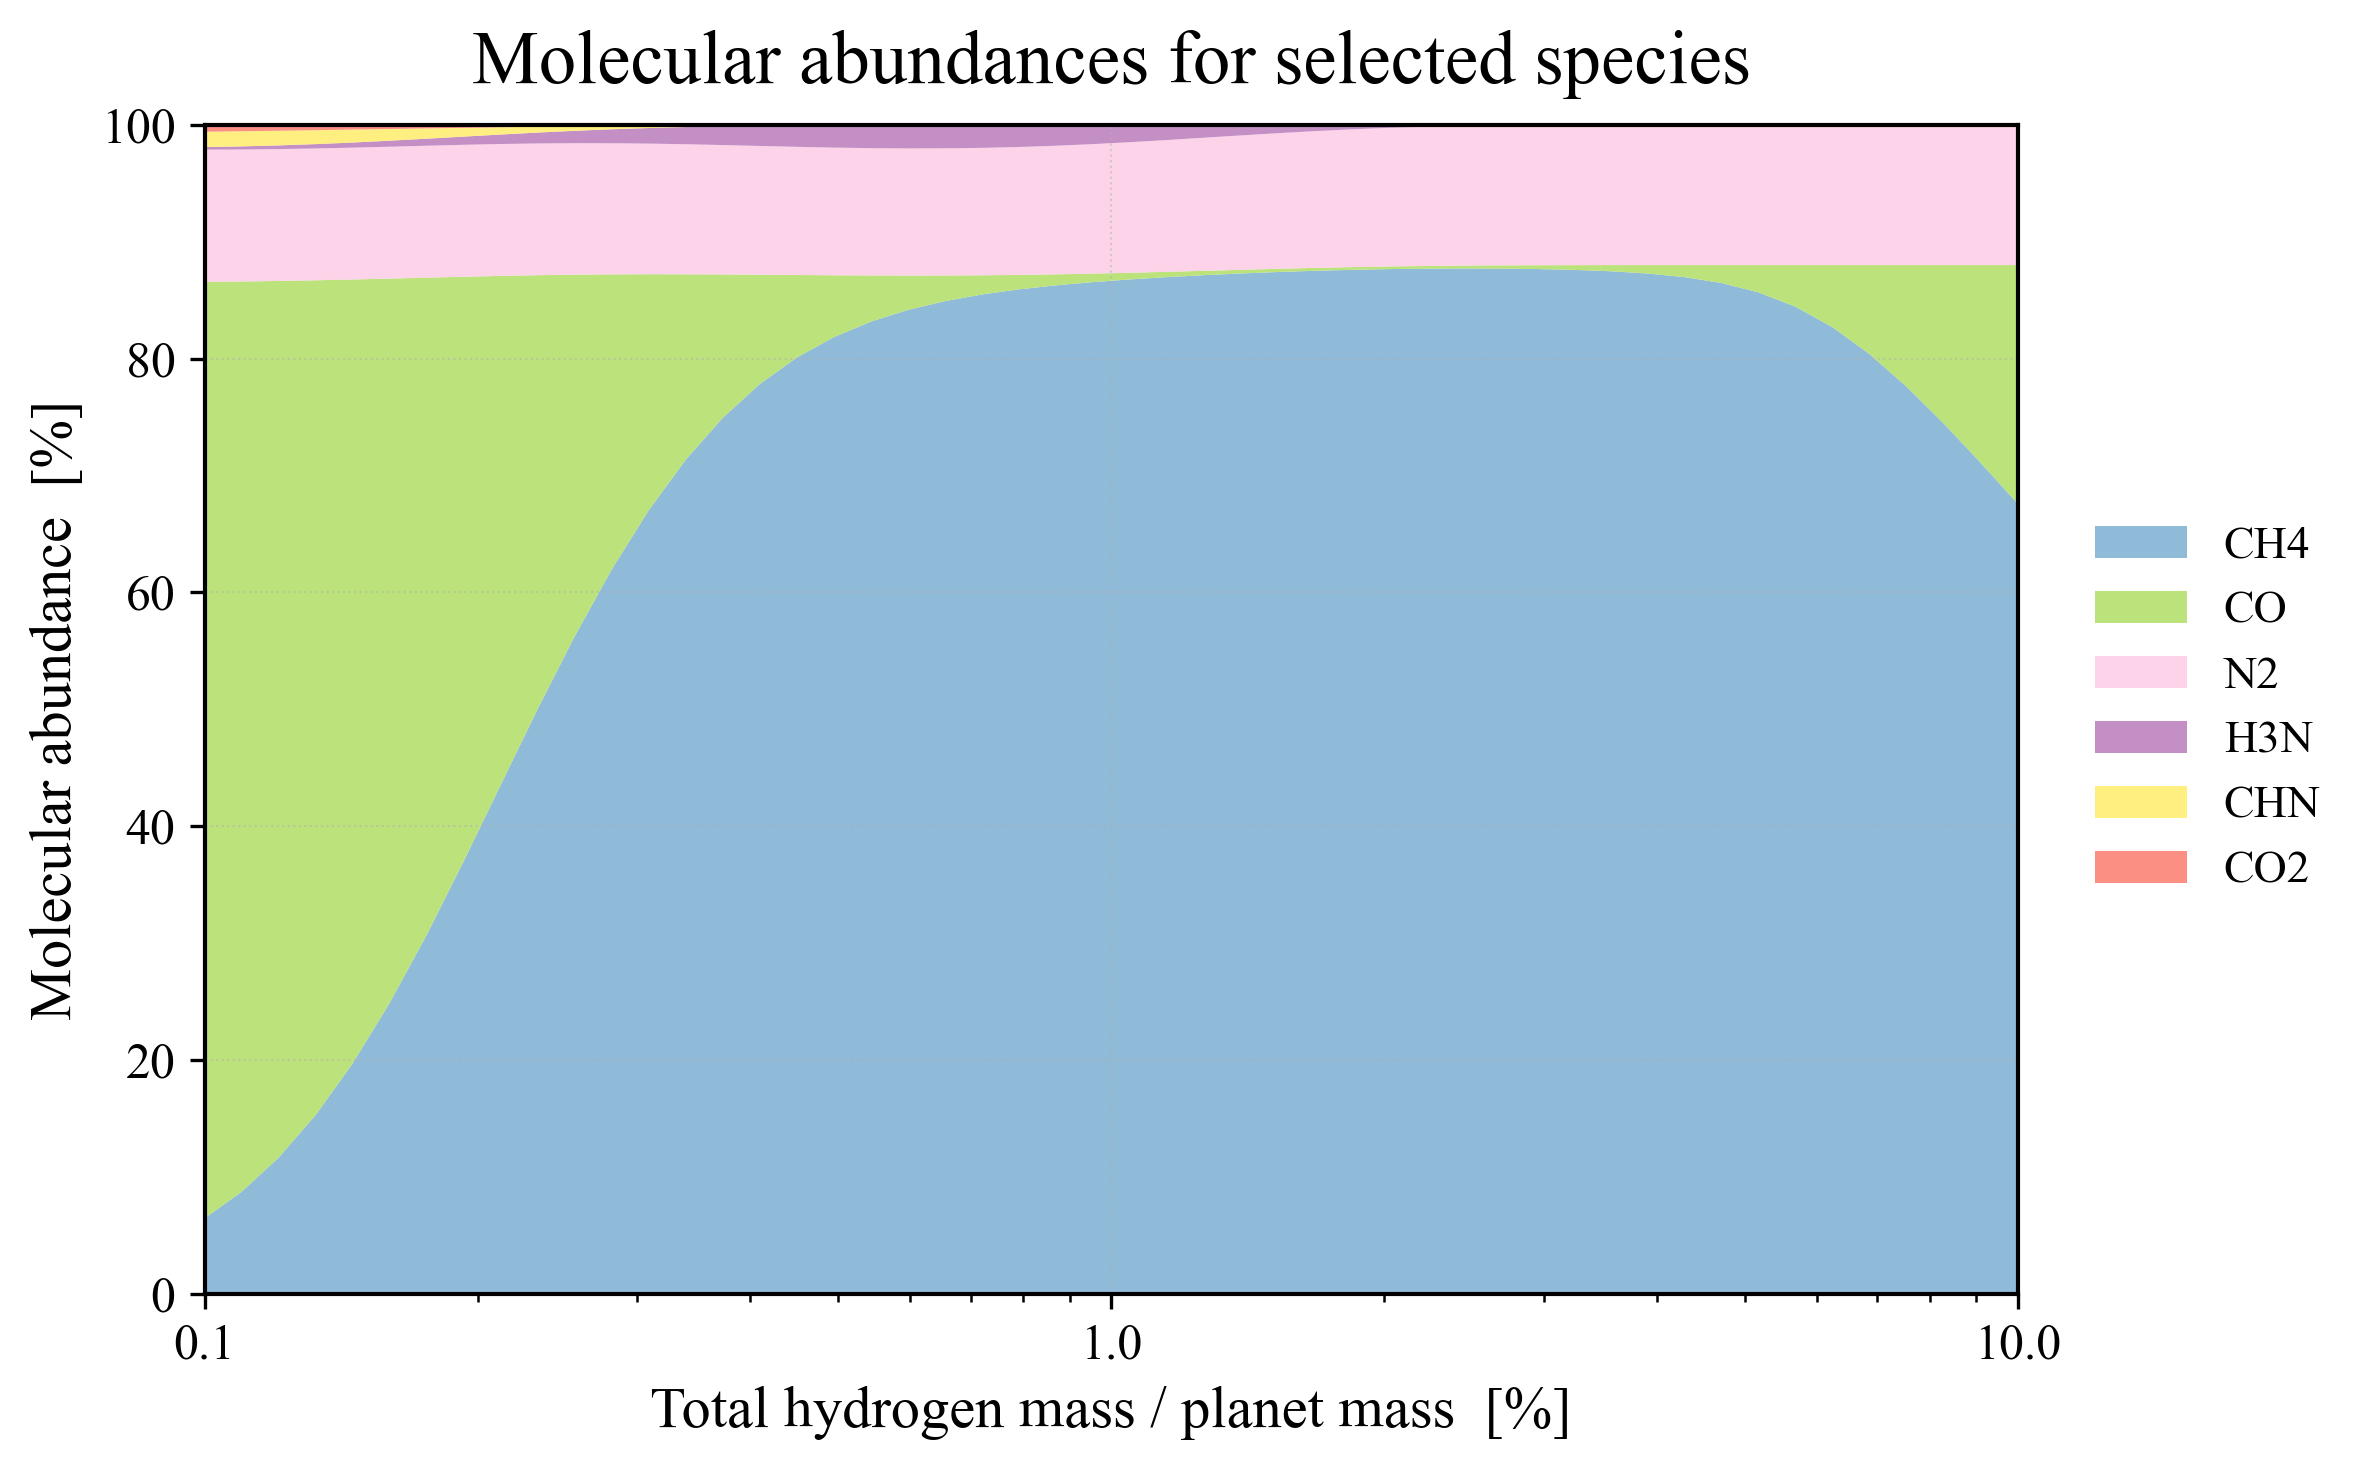

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.cm import get_cmap
from matplotlib.ticker import ScalarFormatter

# ===========================================================
# NATURE-STYLE GLOBAL APPEARANCE
# ===========================================================
def set_nature_style():
    plt.rcdefaults()
    plt.rcParams["font.family"] = "serif"
    plt.rcParams["font.serif"] = ["Times New Roman", "DejaVu Serif"]
    plt.rcParams["axes.labelsize"] = 14
    plt.rcParams["xtick.labelsize"] = 12
    plt.rcParams["ytick.labelsize"] = 12
    plt.rcParams["legend.fontsize"] = 11
    plt.rcParams["axes.linewidth"] = 1.0
    plt.rcParams["axes.grid"] = True
    plt.rcParams["grid.linestyle"] = ":"
    plt.rcParams["grid.linewidth"] = 0.5
    plt.rcParams["grid.alpha"] = 0.5


# ===========================================================
# COLOR MANAGER
# ===========================================================
def assign_colors(all_species):
    cmap = get_cmap("Set3")
    color_list = cmap(np.linspace(0, 1, len(all_species)))
    return {species: color_list[i] for i, species in enumerate(all_species)}


# ===========================================================
# INTERNAL STACKPLOT DRAWER
# ===========================================================
def plot_single_stackplot(
    X,
    df_percent,
    species_colors,
    title,
    outfile
):
    set_nature_style()

    fig, ax = plt.subplots(figsize=(8, 5), dpi=300)

    # Colors for the species included in this particular figure
    colors = [species_colors[s] for s in df_percent.columns]

    ax.stackplot(
        X,
        df_percent.values.T,
        labels=df_percent.columns,
        colors=colors,
        alpha=0.88,
        linewidth=0
    )

    # X-axis formatting
    ax.set_xscale("log")
    ax.set_xlim(X.min(), X.max())
    ax.set_ylim(0, 100)

    fmt = ScalarFormatter()
    fmt.set_scientific(False)
    ax.xaxis.set_major_formatter(fmt)

    # Labels with Nature-style compact formatting
    ax.set_xlabel("Total hydrogen mass / planet mass  [%]", fontsize=14)
    ax.set_ylabel("Molecular abundance  [%]", fontsize=14)

    # Slightly smaller, cleaner title
    ax.set_title(title, fontsize=18, pad=10)

    # Legend (cleaner, less dominant)
    ax.legend(
        loc="center left",
        bbox_to_anchor=(1.02, 0.5),
        fontsize=11,
        title_fontsize=12,
        frameon=False  # Nature often uses frame-less legends for cleaner appearance
    )

    plt.tight_layout()
    plt.savefig(outfile, dpi=300, bbox_inches="tight")
    plt.show()


# ===========================================================
# MAIN FUNCTION (creates full + subset figures)
# ===========================================================
def plot_abundance_two_figures(
    excel_file,
    full_species_sheets,
    subset_species_sheets
):

    # Read H / planet mass
    df_H = pd.read_excel(excel_file, sheet_name="element_H")
    df_planet = pd.read_excel(excel_file, sheet_name="planet")

    planet_mass = df_planet["planet_mass"].iloc[0]
    X = df_H["total_mass"] / planet_mass * 100  # hydrogen fraction

    # Load data for both full + subset species
    all_sheets = list(dict.fromkeys(full_species_sheets + subset_species_sheets))
    species_data = {}

    for sp in all_sheets:
        df_sp = pd.read_excel(excel_file, sheet_name=sp)
        atm = df_sp["atmosphere_moles"]
        dis = df_sp["dissolved_moles"]
        con = df_sp["condensed_mass"] if "condensed_mass" in df_sp.columns else 0
        species_data[sp.replace("_g", "")] = atm + dis + con

    df_all_mass = pd.DataFrame(species_data)

    # Stable colors for all species across figures
    species_colors = assign_colors(df_all_mass.columns.tolist())

    # ----------------------------------------------------
    # FULL SET FIGURE
    # ----------------------------------------------------
    full_species = [s.replace("_g", "") for s in full_species_sheets]
    df_full = df_all_mass[full_species]
    df_full_percent = df_full.div(df_full.sum(axis=1), axis=0) * 100
    df_full_percent = df_full_percent[df_full_percent.mean().sort_values(ascending=False).index]

    plot_single_stackplot(
        X,
        df_full_percent,
        species_colors,
        title="Molecular abundances across full volatile inventory",
        outfile="abundance_full_nature.png"
    )

    # ----------------------------------------------------
    # SUBSET FIGURE
    # ----------------------------------------------------
    subset_species = [s.replace("_g", "") for s in subset_species_sheets]
    df_subset = df_all_mass[subset_species]
    df_subset_percent = df_subset.div(df_subset.sum(axis=1), axis=0) * 100
    df_subset_percent = df_subset_percent[df_subset_percent.mean().sort_values(ascending=False).index]

    plot_single_stackplot(
        X,
        df_subset_percent,
        species_colors,
        title="Molecular abundances for selected species",
        outfile="abundance_subset_nature.png"
    )


# ===========================================================
# EXAMPLE CALL
# ===========================================================
full_species = [
    "H2O_g", "H2_g", "CO2_g", "CH4_g", "CO_g",
    "N2_g", "H3N_g", "He_g", "CHN_g"
]

subset_species = [
    "CO2_g", "CH4_g", "CO_g", "N2_g", "H3N_g", "CHN_g"
]

plot_abundance_two_figures(
    excel_file="THEREALEST.xlsx",
    full_species_sheets=full_species,
    subset_species_sheets=subset_species
)


/var/folders/l6/yw7hsmzx1czfjt3n32sfq_w00000gn/T/ipykernel_7378/2737634240.py:29: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = get_cmap("Set3")


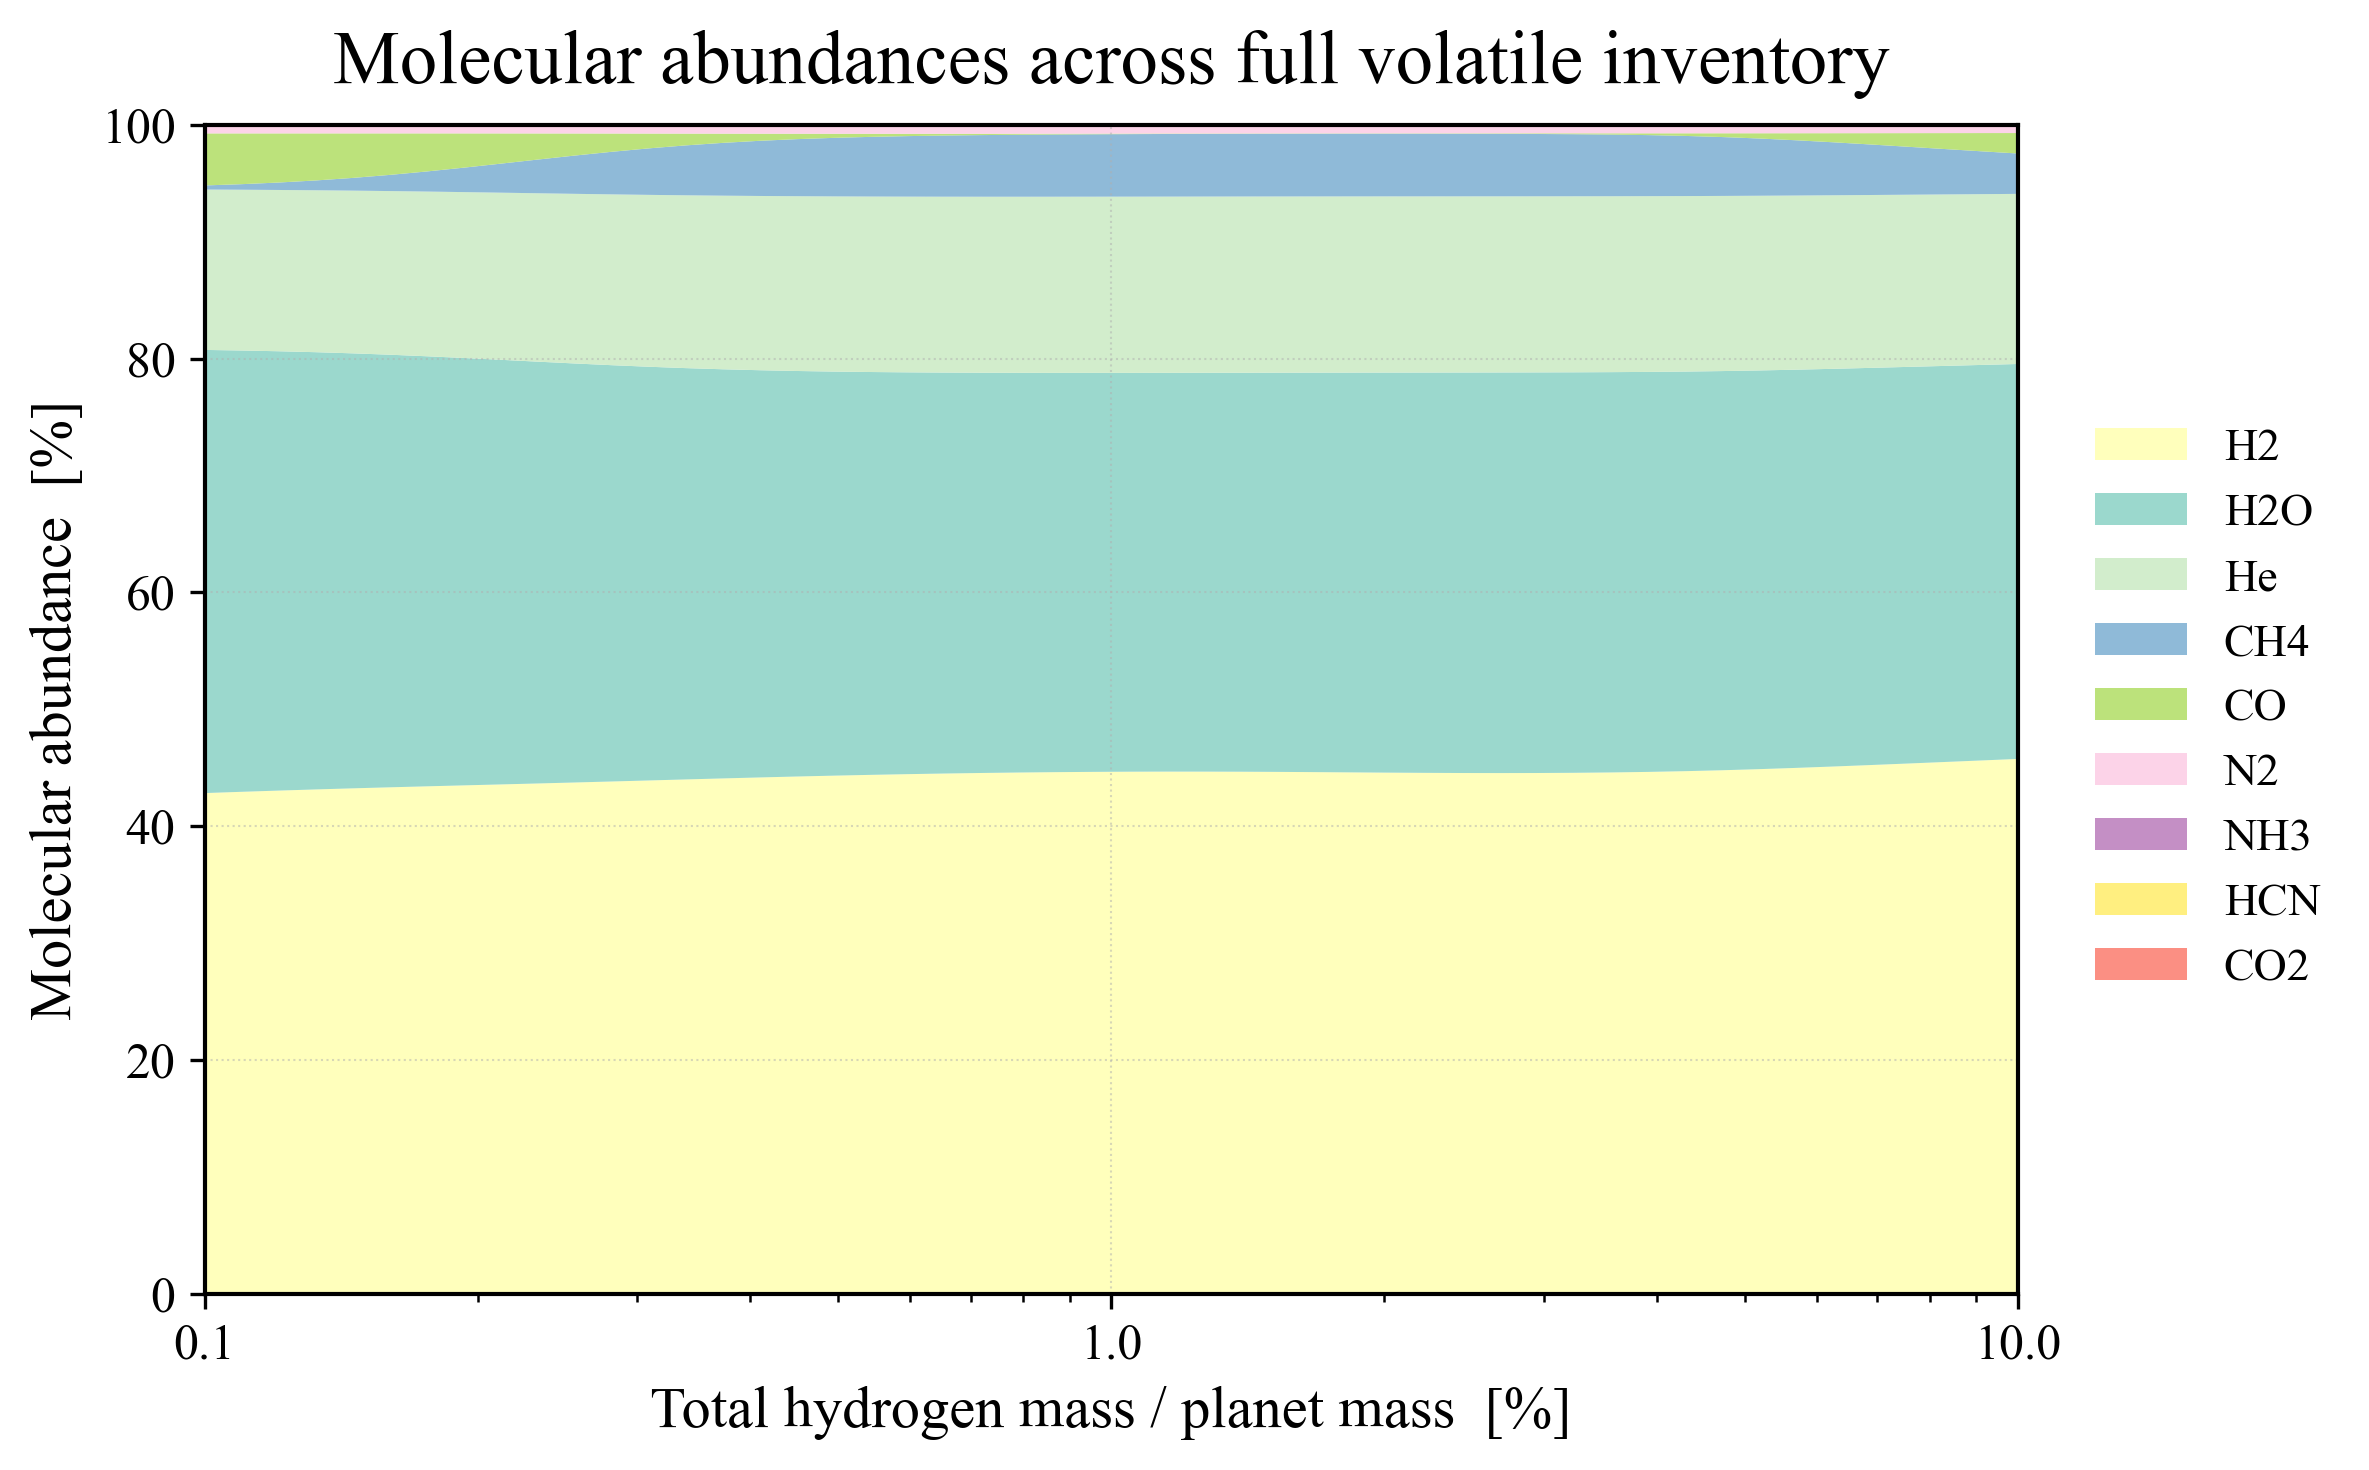

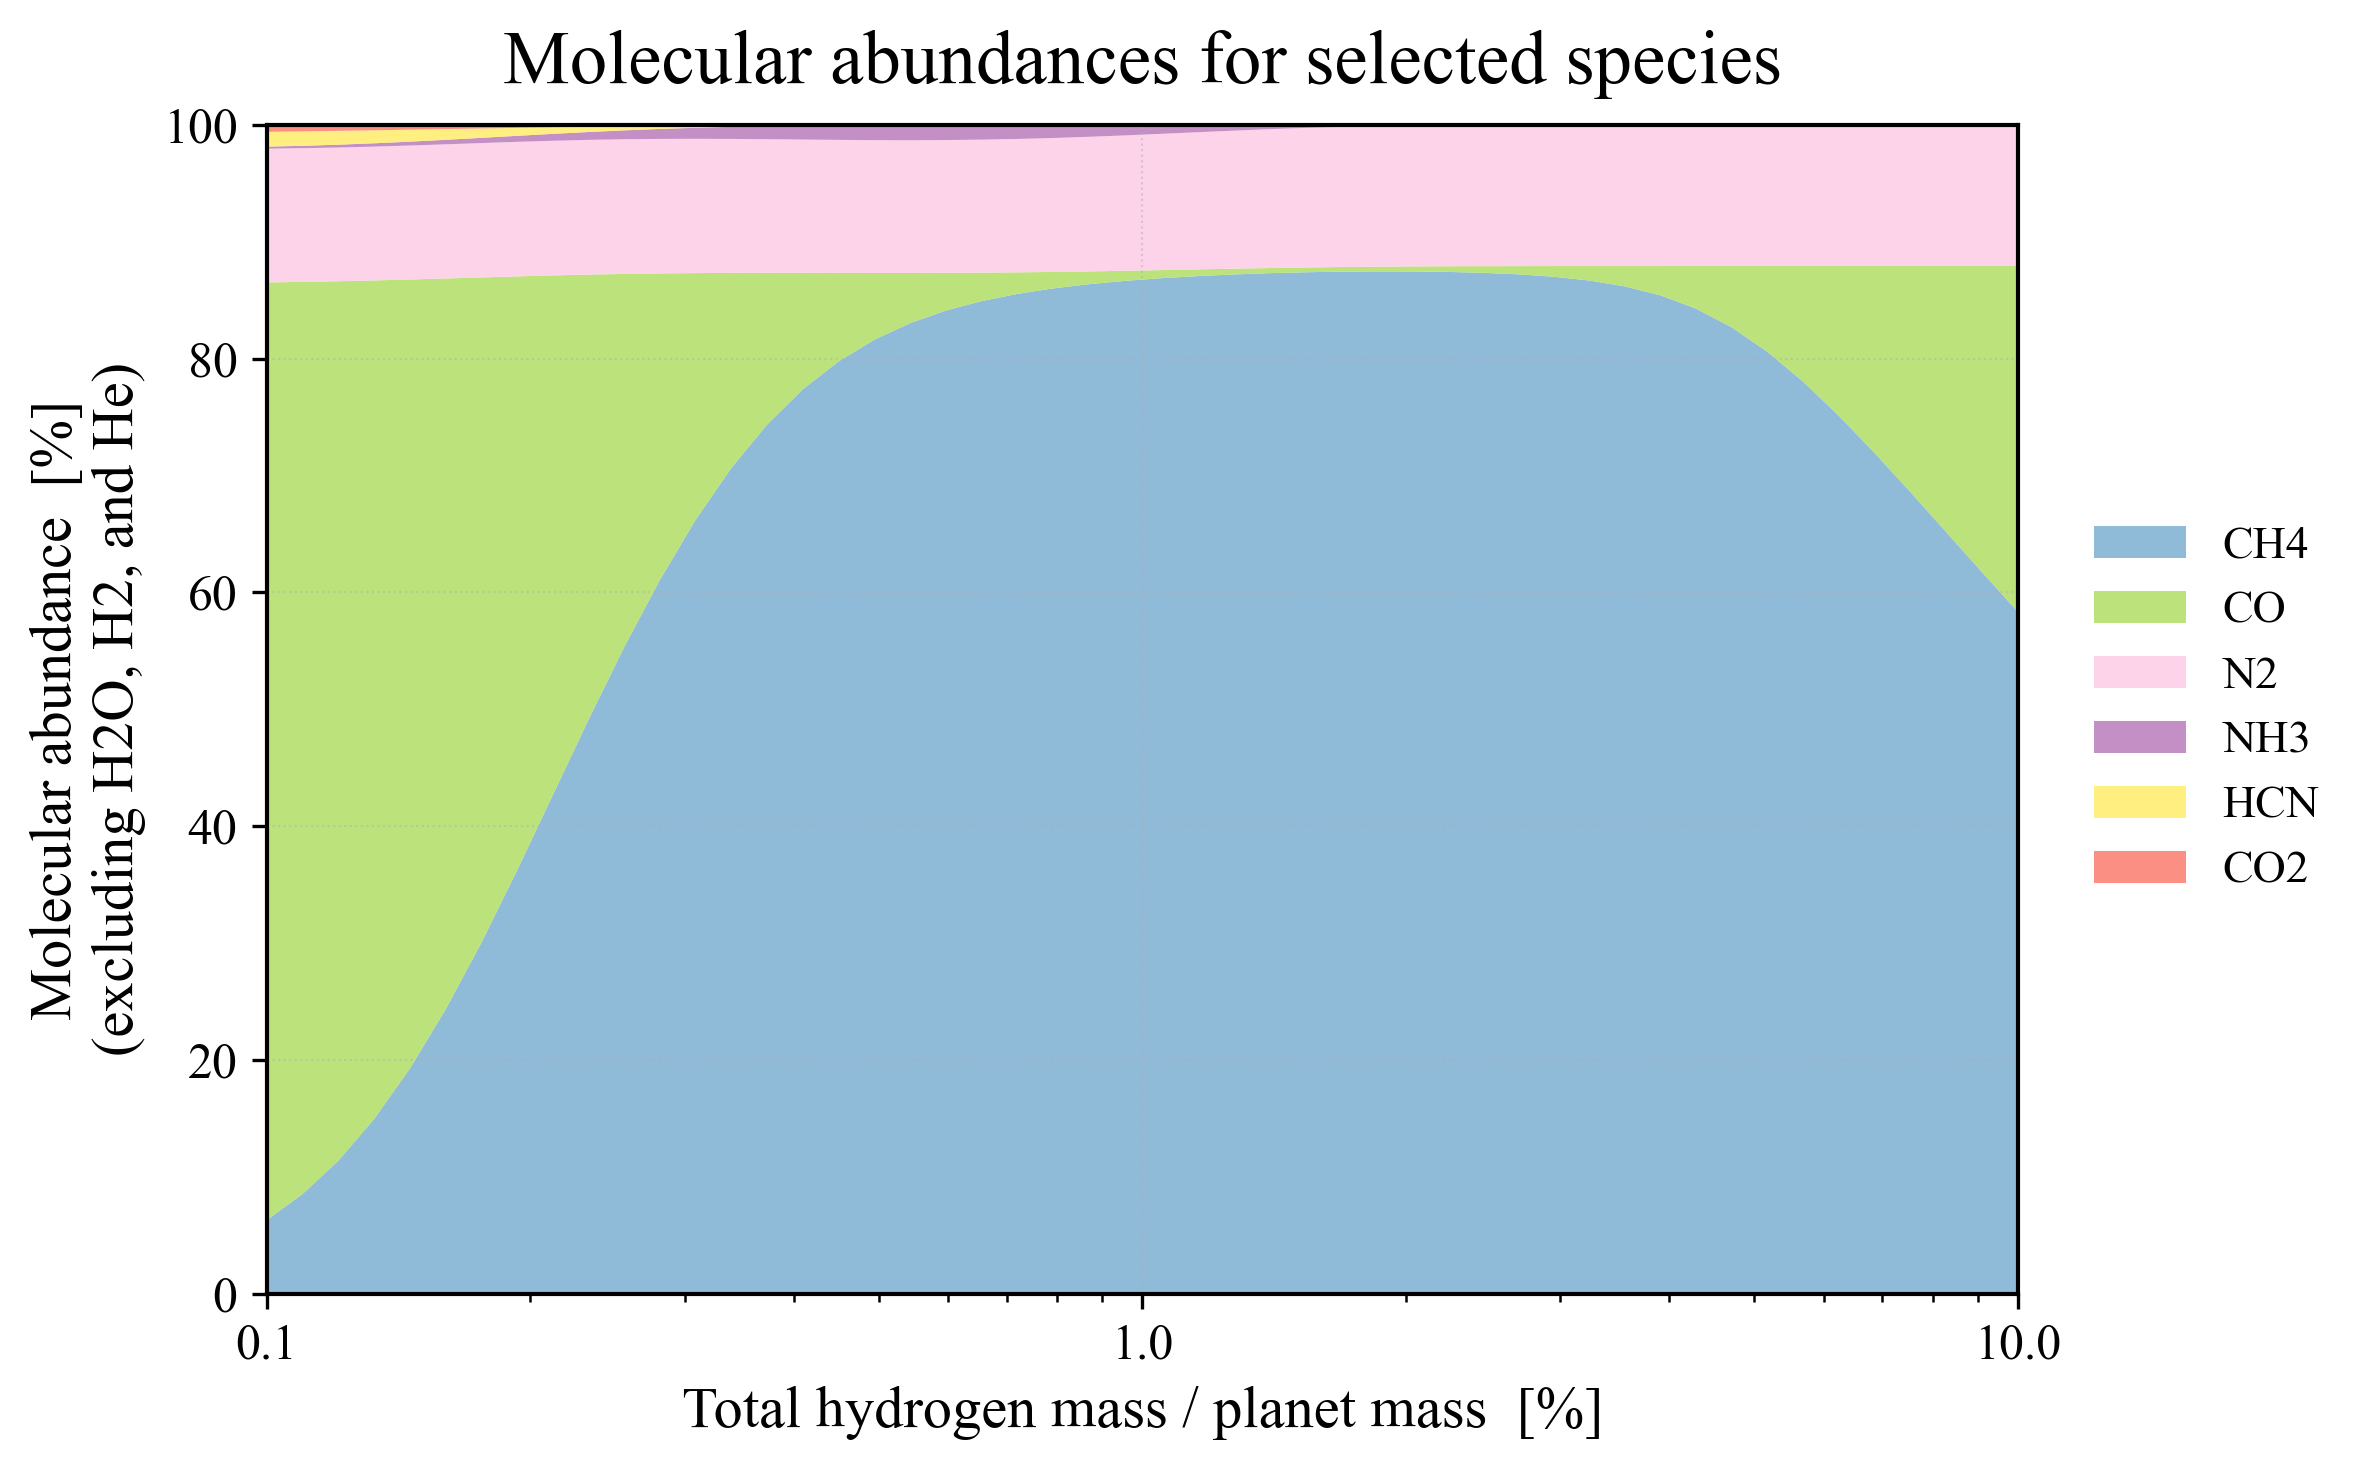

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.cm import get_cmap
from matplotlib.ticker import ScalarFormatter

# ===========================================================
# NATURE-STYLE GLOBAL APPEARANCE
# ===========================================================
def set_nature_style():
    plt.rcdefaults()
    plt.rcParams["font.family"] = "serif"
    plt.rcParams["font.serif"] = ["Times New Roman", "DejaVu Serif"]
    plt.rcParams["axes.labelsize"] = 14
    plt.rcParams["xtick.labelsize"] = 12
    plt.rcParams["ytick.labelsize"] = 12
    plt.rcParams["legend.fontsize"] = 11
    plt.rcParams["axes.linewidth"] = 1.0
    plt.rcParams["axes.grid"] = True
    plt.rcParams["grid.linestyle"] = ":"
    plt.rcParams["grid.linewidth"] = 0.5
    plt.rcParams["grid.alpha"] = 0.5


# ===========================================================
# COLOR MANAGER
# ===========================================================
def assign_colors(all_species):
    cmap = get_cmap("Set3")
    color_list = cmap(np.linspace(0, 1, len(all_species)))
    return {species: color_list[i] for i, species in enumerate(all_species)}


# ===========================================================
# INTERNAL STACKPLOT DRAWER
# ===========================================================
def plot_single_stackplot(
    X,
    df_percent,
    species_colors,
    title,
    outfile
):
    set_nature_style()

    fig, ax = plt.subplots(figsize=(8, 5), dpi=300)

    colors = [species_colors[s] for s in df_percent.columns]

    ax.stackplot(
        X,
        df_percent.values.T,
        labels=df_percent.columns,
        colors=colors,
        alpha=0.88,
        linewidth=0
    )

    ax.set_xscale("log")
    ax.set_xlim(X.min(), X.max())
    ax.set_ylim(0, 100)

    fmt = ScalarFormatter()
    fmt.set_scientific(False)
    ax.xaxis.set_major_formatter(fmt)

    if title == "Molecular abundances for selected species":
        ax.set_xlabel("Total hydrogen mass / planet mass  [%]", fontsize=14)
        ax.set_ylabel("Molecular abundance  [%]\n(excluding H2O, H2, and He)", fontsize=14)
    else:
        ax.set_xlabel("Total hydrogen mass / planet mass  [%]", fontsize=14)
        ax.set_ylabel("Molecular abundance  [%]", fontsize=14)

    ax.set_title(title, fontsize=18, pad=10)

    ax.legend(
        loc="center left",
        bbox_to_anchor=(1.02, 0.5),
        fontsize=11,
        title_fontsize=12,
        frameon=False
    )

    plt.tight_layout()
    plt.savefig(outfile, dpi=300, bbox_inches="tight")
    plt.show()


# ===========================================================
# MAIN FUNCTION (creates full + subset figures)
# ===========================================================
def plot_abundance_two_figures(
    excel_file,
    full_species_sheets,
    subset_species_sheets
):

    # Read H / planet mass
    df_H = pd.read_excel(excel_file, sheet_name="element_H")
    df_planet = pd.read_excel(excel_file, sheet_name="planet")

    planet_mass = df_planet["planet_mass"].iloc[0]
    X = df_H["total_mass"] / planet_mass * 100

    # Load mass data
    all_sheets = list(dict.fromkeys(full_species_sheets + subset_species_sheets))
    species_data = {}

    for sp in all_sheets:
        df_sp = pd.read_excel(excel_file, sheet_name=sp)
        atm = df_sp["atmosphere_moles"]
        dis = df_sp["dissolved_moles"]
        con = df_sp["condensed_mass"] if "condensed_mass" in df_sp.columns else 0
        species_data[sp.replace("_g", "")] = atm + dis + con

    df_all_mass = pd.DataFrame(species_data)

    # ----------------------------------------
    # FIX LABELS FOR DISPLAY
    # (Data remains unchanged, only the names)
    # ----------------------------------------
    df_all_mass.rename(columns={"H3N": "NH3", "CHN": "HCN"}, inplace=True)

    # Stable color mapping
    species_colors = assign_colors(df_all_mass.columns.tolist())

    # ----------------------------------------------------
    # FULL FIGURE
    # ----------------------------------------------------
    full_species = [s.replace("_g", "") for s in full_species_sheets]
    # Apply same renaming to selection
    full_species = [ "NH3" if s=="H3N" else "HCN" if s=="CHN" else s for s in full_species ]

    df_full = df_all_mass[full_species]
    df_full_percent = df_full.div(df_full.sum(axis=1), axis=0) * 100
    df_full_percent = df_full_percent[df_full_percent.mean().sort_values(ascending=False).index]

    plot_single_stackplot(
        X,
        df_full_percent,
        species_colors,
        title="Molecular abundances across full volatile inventory",
        outfile="abundance_full_nature.png"
    )

    # ----------------------------------------------------
    # SUBSET FIGURE
    # ----------------------------------------------------
    subset_species = [s.replace("_g", "") for s in subset_species_sheets]
    subset_species = [ "NH3" if s=="H3N" else "HCN" if s=="CHN" else s for s in subset_species ]

    df_subset = df_all_mass[subset_species]
    df_subset_percent = df_subset.div(df_subset.sum(axis=1), axis=0) * 100
    df_subset_percent = df_subset_percent[df_subset_percent.mean().sort_values(ascending=False).index]

    plot_single_stackplot(
        X,
        df_subset_percent,
        species_colors,
        title="Molecular abundances for selected species",
        outfile="abundance_subset_nature.png"
    )


# ===========================================================
# EXAMPLE CALL
# ===========================================================
full_species = [
    "H2O_g", "H2_g", "CO2_g", "CH4_g", "CO_g",
    "N2_g", "H3N_g", "He_g", "CHN_g"
]

subset_species = [
    "CO2_g", "CH4_g", "CO_g", "N2_g", "H3N_g", "CHN_g"
]

plot_abundance_two_figures(
    excel_file="THEREALEST.xlsx",
    full_species_sheets=full_species,
    subset_species_sheets=subset_species
)
